In [64]:
import matplotlib.pyplot as plt
import pandas as pd
from pypalettes import load_cmap
import numpy as np

cmap = load_cmap("CarolMan")

RESULTS = "../results/"

city_lr_metrics       = pd.read_csv(RESULTS + "city_linreg_metrics.csv")
city_lr_coefs         = pd.read_csv(RESULTS + "city_linreg_coefs.csv")
city_trees_metrics    = pd.read_csv(RESULTS + "city_trees_metrics.csv")
city_trees_importance = pd.read_csv(RESULTS + "city_trees_importance.csv")
district_lr_metrics   = pd.read_csv(RESULTS + "district_linreg_metrics.csv")
district_lr_coefs     = pd.read_csv(RESULTS + "district_linreg_coefs.csv")


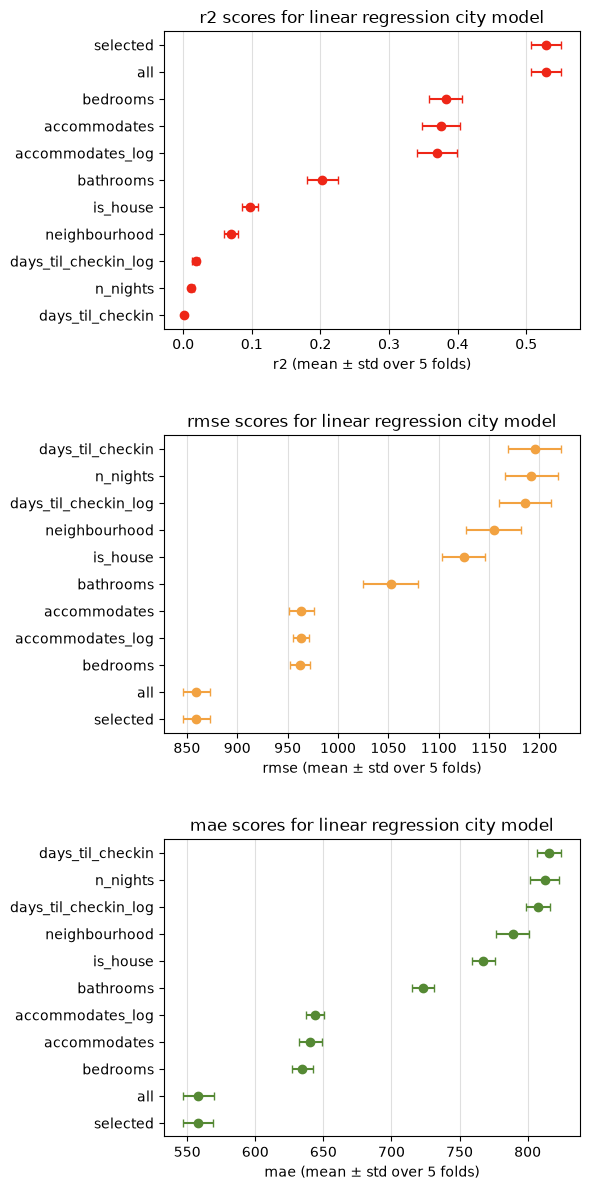

In [74]:
metrics = ["r2", "rmse", "mae"]
stds = ["r2_std", "rmse_std", "mae_std"]

fig, axes = plt.subplots(3, 1, figsize = (6, 12))
for i, (met, std) in enumerate(zip(metrics, stds)):
    ax = axes[i]
    city_lr_metrics = city_lr_metrics.sort_values(met)
    ax.errorbar(city_lr_metrics[met], city_lr_metrics["variable"], xerr=city_lr_metrics[std], 
             fmt="o", capsize=3, color = cmap(i))
    ax.set_title(f'{met} scores for linear regression city model')
    ax.set_xlabel(f'{met} (mean ± std over 5 folds)')
    ax.grid(axis = 'x',alpha = 0.4)
plt.tight_layout(h_pad=3)
plt.show()



In [66]:
display(district_lr_metrics)

,model,district,variable,n_variables,n,r2,r2_std,rmse,rmse_std,mae,mae_std
0,single,Bjerke,is_house,1,184,0.126215,0.094673,726.906039,256.611789,512.685588,154.439267
1,single,Bjerke,accommodates_log,1,184,0.315724,0.186631,649.052569,244.121811,449.556847,96.331690
2,single,Bjerke,accommodates,1,184,0.360835,0.183050,613.975531,223.338304,430.276911,95.257502
3,single,Bjerke,bedrooms,1,184,0.429424,0.133690,593.597044,206.942960,408.575004,96.618700
4,single,Bjerke,bathrooms,1,184,0.197252,0.101509,681.163038,226.037835,482.442675,101.982418
...,...,...,...,...,...,...,...,...,...,...,...
135,single,Østensjø,n_nights,1,189,-0.019875,0.067810,1108.515284,178.192407,804.403094,114.482532
136,single,Østensjø,days_til_checkin_log,1,189,-0.013961,0.025417,1101.299733,176.077667,803.231736,108.851786
137,single,Østensjø,days_til_checkin,1,189,-0.010490,0.019299,1104.497317,172.914404,800.113212,107.780643
138,all,Østensjø,all,6,189,0.548044,0.149639,837.269874,131.170983,547.236788,51.215693


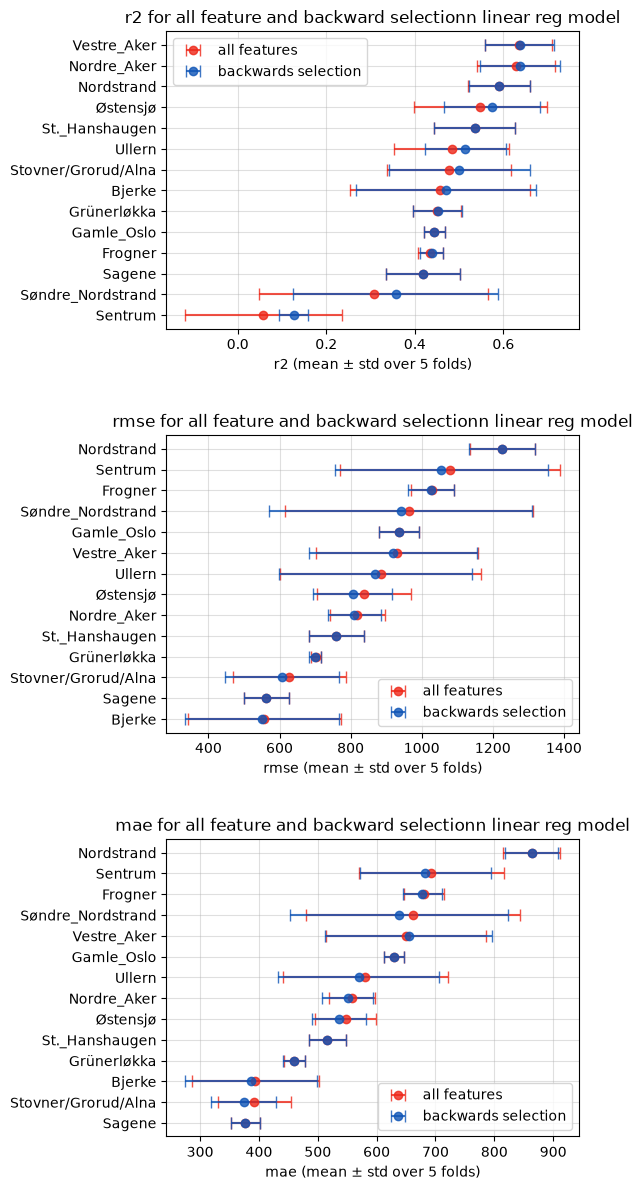

In [67]:
fig, axes = plt.subplots(3,1, figsize = (6,12))

for i, (met, std) in enumerate(zip(metrics, stds)):
    ax = axes[i]

    district_lr_metrics = district_lr_metrics.sort_values(met)
    all_subset = district_lr_metrics[district_lr_metrics["model"] == "all"]
    backwards_subset = district_lr_metrics[district_lr_metrics["model"] == "backward"]

    ax.errorbar(all_subset[met], all_subset["district"], xerr=all_subset[std], fmt="o", capsize=4, color = cmap(0), alpha = 0.8, label = 'all features')
    ax.errorbar(backwards_subset[met], backwards_subset["district"], xerr=backwards_subset[std], fmt="o", capsize=4, color = cmap(3), alpha = 0.8, label = 'backwards selection')
    ax.set_xlabel(f'{met} (mean ± std over 5 folds)')
    ax.set_title(f'{met} for all feature and backward selectionn linear reg model')
    ax.grid(alpha = 0.4)
    ax.legend()


plt.tight_layout(h_pad= 3)
plt.show()

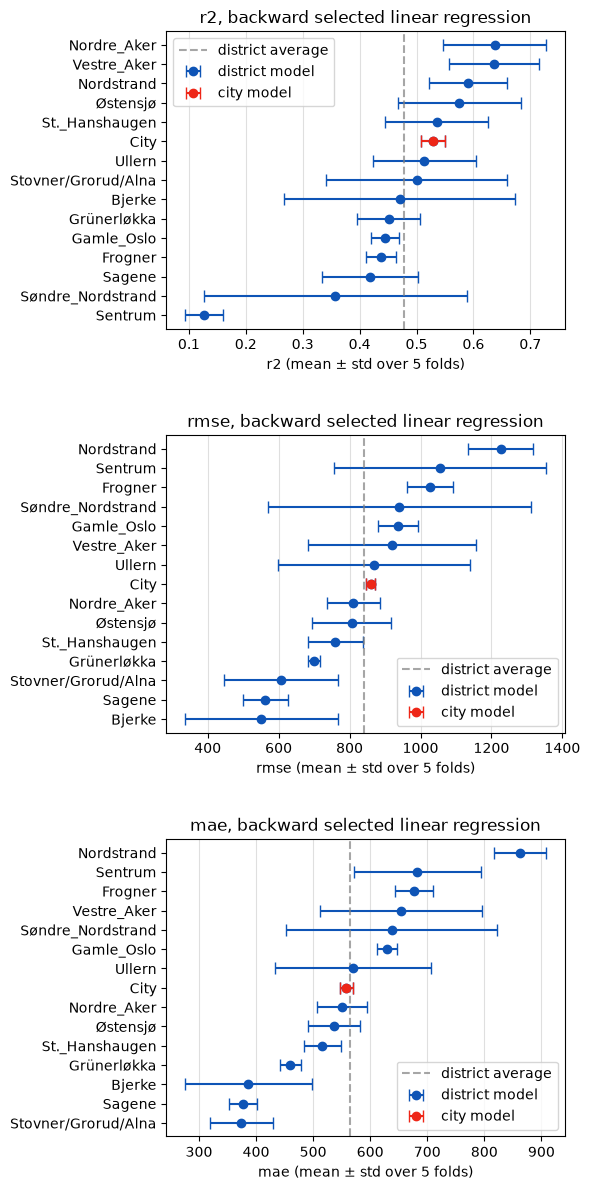

In [73]:
city_bw = city_lr_metrics[city_lr_metrics["model"] == "backward"].assign(district="City")
district_bw = district_lr_metrics[district_lr_metrics["model"] == "backward"]
backward = pd.concat([city_bw, district_bw])

fig, axes = plt.subplots(3, 1, figsize=(6, 12))

for i, (met, std) in enumerate(zip(metrics, stds)):
    ax = axes[i]
    data = backward.sort_values(met)
    is_city = data["district"] == "City"

    ax.errorbar(data[met], data["district"], xerr=data[std], fmt="o", capsize=4, label="district model",
                color = cmap(3))
    ax.errorbar(data.loc[is_city, met], data.loc[is_city, "district"], xerr=data.loc[is_city, std],
                fmt="o", capsize=4, color=cmap(0), label="city model")
    ax.axvline(district_bw[met].mean(), color="grey", linestyle="--", label="district average", alpha = 0.7)
    ax.set_xlabel(f"{met} (mean ± std over 5 folds)")
    ax.set_title(f"{met}, backward selected linear regression")
    ax.grid(axis = 'x', alpha=0.4)
    ax.legend()

plt.tight_layout(h_pad=3)
plt.show()

In [69]:
display(city_lr_coefs)

,model,variable,column,coef
0,single,is_house,is_house,0.498751
1,single,accommodates_log,accommodates_log,0.591223
2,single,accommodates,accommodates,0.154459
3,single,bedrooms,bedrooms,0.291393
4,single,bathrooms,bathrooms,0.560020
5,single,n_nights,n_nights,-0.017133
6,single,days_til_checkin_log,days_til_checkin_log,-0.037327
7,single,days_til_checkin,days_til_checkin,-0.000294
8,single,neighbourhood,Bjerke,-0.323069
9,single,neighbourhood,Frogner,-0.014187


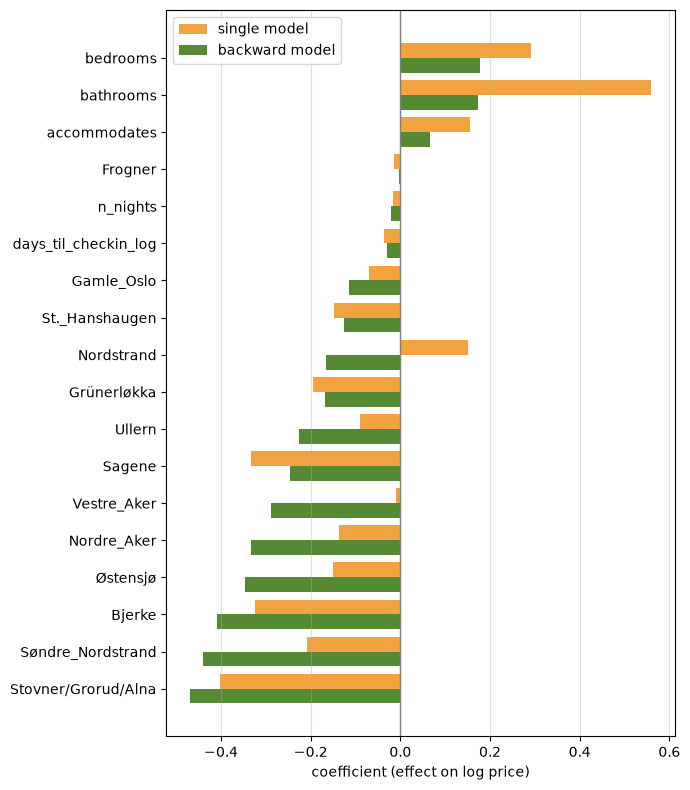

In [72]:
single = city_lr_coefs[city_lr_coefs["model"] == "single"]
backward = city_lr_coefs[city_lr_coefs["model"] == "backward"]

both = pd.merge(single, backward, on="column", suffixes=("_single", "_backward"))
both = both.sort_values("coef_backward")

y = np.arange(len(both))     
height = 0.4                  

plt.figure(figsize=(7, 8))
plt.barh(y + height/2, both["coef_single"], height, label="single model", color = cmap(1))
plt.barh(y - height/2, both["coef_backward"], height, label="backward model", color = cmap(2))
plt.yticks(y, both["column"])
plt.axvline(0, color="grey", linewidth=1)
plt.xlabel("coefficient (effect on log price)")
plt.legend()
plt.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

In [75]:
display(city_trees_metrics)

,model,n_features,n,r2,r2_std,rmse,rmse_std,mae,mae_std
0,rf,8,7353,0.565509,0.013643,817.876606,7.914646,532.839795,1.097243
1,gb,8,7353,0.572527,0.019397,809.184069,6.383687,527.561582,4.435014


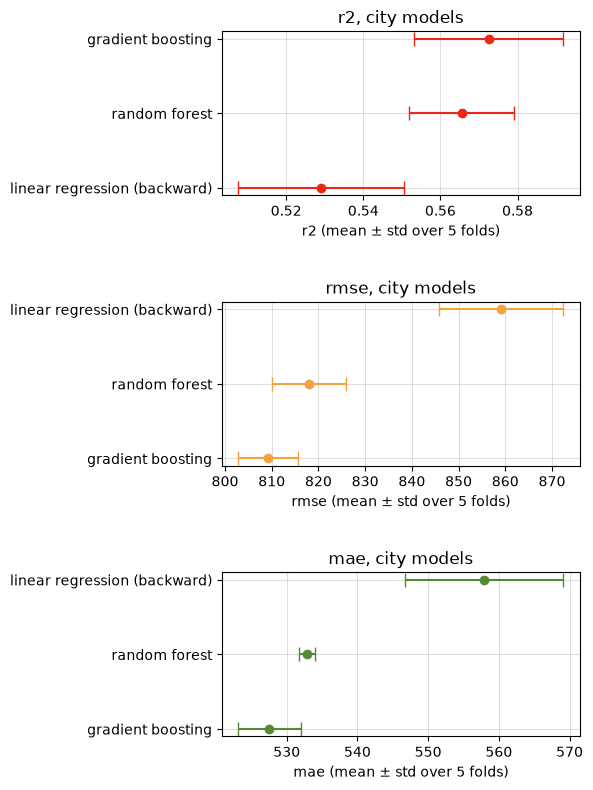

In [78]:
lr_backward = city_lr_metrics[city_lr_metrics["model"] == "backward"]
models = pd.concat([lr_backward, city_trees_metrics])
models["model"] = models["model"].replace({"backward": "linear regression (backward)",
                                           "rf": "random forest",
                                           "gb": "gradient boosting"})

metrics = ["r2", "rmse", "mae"]
stds = ["r2_std", "rmse_std", "mae_std"]

fig, axes = plt.subplots(3, 1, figsize=(6, 8))

for i, (met, std) in enumerate(zip(metrics, stds)):
    ax = axes[i]
    data = models.sort_values(met)  

    ax.errorbar(data[met], data["model"], xerr=data[std], fmt="o", capsize=5, color = cmap(i))
    ax.set_xlabel(f"{met} (mean ± std over 5 folds)")
    ax.set_title(f"{met}, city models")
    ax.grid(alpha=0.4)

plt.tight_layout(h_pad=3)
plt.show()

In [79]:
display(city_trees_importance)

,model,method,feature,mean,std
0,rf,permutation,is_house,0.003167,0.002271
1,rf,permutation,accommodates,0.140788,0.005628
2,rf,permutation,bedrooms,0.263119,0.014421
3,rf,permutation,bathrooms,0.048659,0.005942
4,rf,permutation,n_nights,0.033755,0.009828
5,rf,permutation,days_til_checkin,0.034538,0.007153
6,rf,permutation,latitude,0.083082,0.012195
7,rf,permutation,longitude,0.098015,0.014712
8,rf,builtin,is_house,0.030033,0.005715
9,rf,builtin,accommodates,0.198849,0.006323


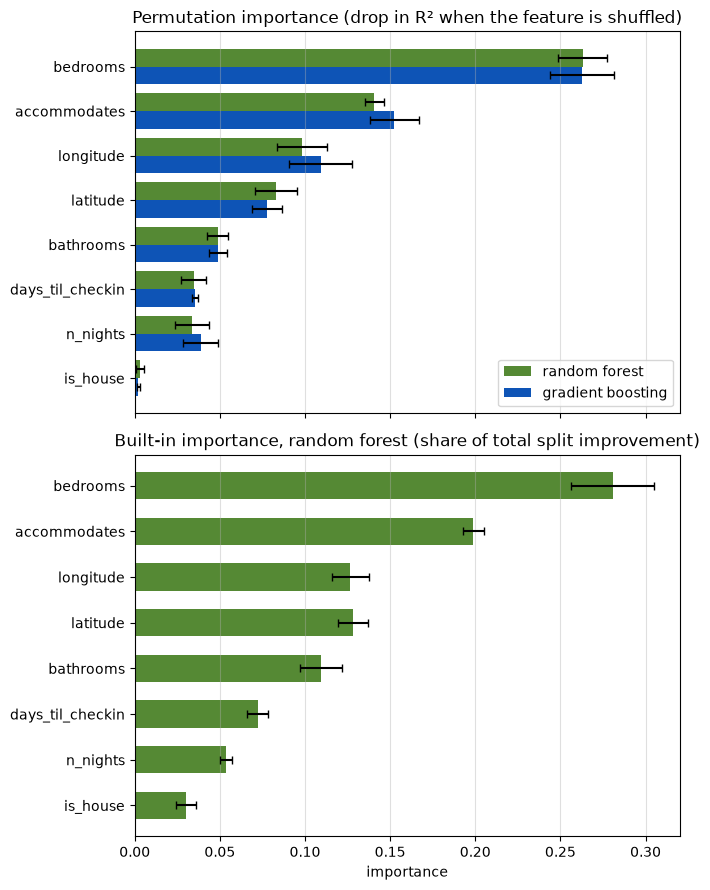

In [81]:
import matplotlib.pyplot as plt
import numpy as np

perm = city_trees_importance[city_trees_importance["method"] == "permutation"]
builtin = city_trees_importance[city_trees_importance["method"] == "builtin"]

# features sorted by random forest permutation importance, most important at the top
order = perm[perm["model"] == "rf"].sort_values("mean")["feature"]
y = np.arange(len(order))
height = 0.4

fig, axes = plt.subplots(2, 1, figsize=(7, 9), sharex=True)

# top: permutation importance, random forest vs gradient boosting
for model, offset, name, color in [("rf", height/2, "random forest", cmap(2)),
                                   ("gb", -height/2, "gradient boosting", cmap(3))]:
    data = perm[perm["model"] == model].set_index("feature").loc[order]
    axes[0].barh(y + offset, data["mean"], height, xerr=data["std"], capsize=3,
                 color=color, label=name)
axes[0].set_title("Permutation importance (drop in R² when the feature is shuffled)")
axes[0].legend()

# bottom: built-in importance, random forest only
data = builtin.set_index("feature").loc[order]
axes[1].barh(y, data["mean"], 0.6, xerr=data["std"], capsize=3, color=cmap(2))
axes[1].set_title("Built-in importance, random forest (share of total split improvement)")
axes[1].set_xlabel("importance")

for ax in axes:
    ax.set_yticks(y, order)
    ax.grid(axis="x", alpha=0.4)

plt.tight_layout()
plt.show()